#1. import libraries

In [85]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import classification_report,confusion_matrix

* imported the libraries for ANN model

#2. importing dataset

In [64]:
from sklearn.datasets import make_classification

In [65]:
data=make_classification()

In [66]:
data

(array([[ 0.31271671, -0.82772494,  0.5601313 , ...,  0.29080597,
          0.25759978,  0.47473958],
        [ 1.8177057 ,  0.27580289, -0.35358689, ...,  0.83621038,
         -0.75568561, -0.00569389],
        [ 0.30007486, -0.88378723, -1.14214192, ..., -1.56815647,
         -0.28762301, -2.52466753],
        ...,
        [-0.50784132,  0.44513079, -0.05669397, ..., -0.64605558,
          0.55184884, -0.09783737],
        [-2.7031841 ,  2.40271807,  0.61484233, ...,  0.61446693,
          0.94100947, -0.18864003],
        [-0.5280801 , -1.80981517,  0.35171111, ...,  0.94386525,
          1.140882  ,  0.20757039]], shape=(100, 20)),
 array([1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1,
        1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0,
        0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1,
        0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1,
        1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1]))

* Imported the Dataset

#3. split X and y

In [67]:
X,y=make_classification(n_samples=1000,n_features=10,n_informative=6,n_redundant=2,n_classes=3,n_clusters_per_class=1,random_state=42)

* splited feature and target as X and y

#4. analyse the features

In [94]:
print(X.shape)
print(y.shape)

(1000, 10)
(1000,)


* 1000 rows, 10 columns

# 5. train_test_split

In [68]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

* training 80%
* testing 20%

#6. Exploring the data

In [69]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 10)
(200, 10)
(800,)
(200,)


In [70]:
print(np.unique(y_train))

[0 1 2]


* It is a Multiclass classification label

#7. Scaling

In [71]:
scaler= StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

* standard scaler is used for scaling

#8. Build the model

In [72]:
model=Sequential()

In [73]:
model.add(Dense(32,activation='relu',input_shape=(X_train.shape[1],)))
model.add(Dense(16,activation='relu'))
model.add(Dense(3,activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


* Used Dense(32,) for input layer
* Used Dense(16,) for hidden layer
* Used Dense(3,) for output layer

#9. compile the model

In [74]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=['accuracy'])

* Sparse categorical crossentrophy used for loss as it is a multiclass classification

#10. Train the model

In [75]:
history=model.fit(X_train,y_train,epochs=20,batch_size=32,validation_split=0.2)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.3656 - loss: 1.1534 - val_accuracy: 0.5250 - val_loss: 1.0259
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5641 - loss: 0.9659 - val_accuracy: 0.6500 - val_loss: 0.9040
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7125 - loss: 0.8476 - val_accuracy: 0.7125 - val_loss: 0.8108
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7594 - loss: 0.7488 - val_accuracy: 0.7063 - val_loss: 0.7294
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7859 - loss: 0.6559 - val_accuracy: 0.7312 - val_loss: 0.6471
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8109 - loss: 0.5715 - val_accuracy: 0.7563 - val_loss: 0.5763
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8297 - loss: 0.4967 - val_accuracy: 0.7812 - val_loss: 0.5074
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8516 - loss: 0.4348 - val_accuracy: 0.8375 - val_los

#11. Evaluating the Model

In [76]:
loss,accuracy=model.evaluate(X_test,y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9350 - loss: 0.2170  


* loss and accuracy has been evaluated with test data

#12. Loss and Accuracy

In [77]:
print("Test Loss",loss)
print("Test Accuracy",accuracy)

Test Loss 0.21701040863990784
Test Accuracy 0.9350000023841858


#13. model prediction

In [78]:
y_pred=model.predict(X_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [82]:
y_pred=np.argmax(y_pred,axis=1)

#14. Comparing actual and predicted value

In [92]:
print(y_pred[:20])

[0 0 2 0 1 0 2 0 0 0 1 1 0 0 1 0 2 2 1 0]


In [93]:
print(y_test[:20])

[0 0 2 0 1 1 2 0 1 0 1 1 0 1 1 1 2 2 1 0]


* around 20 values 3 values has been missed by the model prediction that too label class 1 is missed.

#15. Classification report

In [90]:
class_report=classification_report(y_test,y_pred)

In [91]:
print(class_report)

              precision    recall  f1-score   support

           0       0.89      0.99      0.94        74
           1       0.95      0.85      0.90        66
           2       0.98      0.97      0.97        60

    accuracy                           0.94       200
   macro avg       0.94      0.93      0.94       200
weighted avg       0.94      0.94      0.93       200



#16.Confusion Matrix

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns
cm=confusion_matrix(y_test,y_pred)

#Plotting

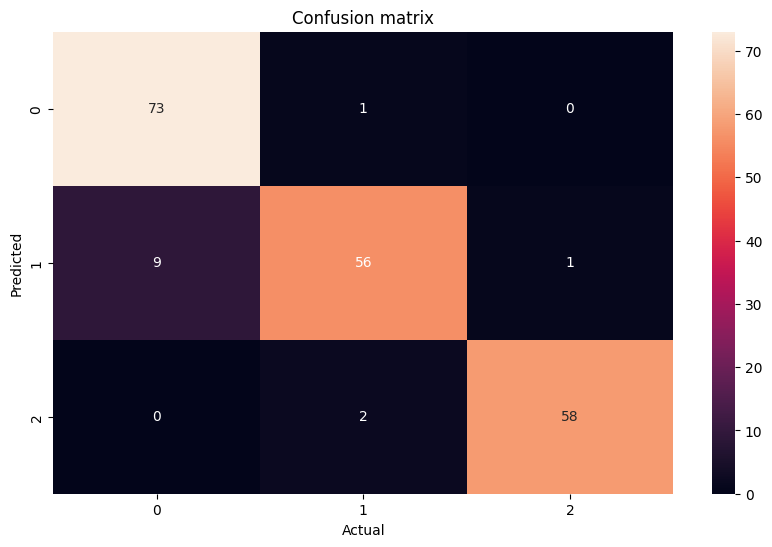

In [88]:
plt.figure(figsize=(10,6))
sns.heatmap(cm,annot=True,fmt='d')
plt.title("Confusion matrix")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()